<h1>Python Homework</h1>
<h2>Lena Dragunova, elsedragunova@edu.hse.ru</h2>
<h3> Homework: automating my training log</h3>

__Content:__
* [1. My routine task](#point1);
* [2. How Python can automate it??](#point2);
* [3. Python code](#point3);
* [4. Tests](#point4);
* [5. Optimized code](#point5);
* [6. Description of my technical solution and ideas for further development of the project](#point6).

<h2> 1. My routine task</h2><a name=point1></a>

I love sports, I regularly train in the gym and trying to get into running. Sometimes I do it alone, sometimes – with my gymsis, both us are iterested in the progress we make. 

![pic of me and my gym friend Arisha](https://github.com/mhlnse/hse/blob/content/gymsiss.jpg?raw=true)

When I am trying to track my workouts, I usually do it in my Saved messages in Telegram (it looks like "жим 100 3 по 8-10,
махи назад в тркнажере 40/45/40 3 по 10,
махи вбок 7.5/7.5/5 10/8/8,
бицепс бедра 3 по 10 25/30/30,
разведения 3 по 10-10-8 37.5/40/40,
мост 65 3 по 10-8-9", which is really messy and confusing!) to write it down in the notebook after the workout. For me, it is essential to track sets, repititions and weight I work with in the gym.
However, it is hard to keep track of my workouts this way. What is more, it can't give me the oppotrunity to see my visualized progress in charts.

<h2> 2. How Python can automate it??</h2><a name=point2></a>

The program reads a text file with my workout notes, an *'exercises.json'* file maps muscle groups to keywords (a dict of lists) and a *'goals.json'* file with my weekly targets (a dict).
A loop goes through the notes line by line, it remembers the current date, uses regular expressions to split every line into exercise, weights, sets and repetitions, turns ranges such as *55-67,5* or *40/45/40* into a list of weights per set, and puts broken lines into a list of tuples together with the reason for rejection.
From the parsed records the code calculates the training volume per muscle group, weekly statistics (sets of training days per week), personal records, progress of every exercise, running pace and breaks longer than four days between workouts. 
I also added an if-elif-else block that gives every week a status (DONE/ALMOST/MISSED) for the gym and running goals, and unknown exercises are collected in a set so that I can add them to the keyword file. The result is a text report saved to a file, and the whole code is split into annotated functions(:

<h2> 3. Python code </h2><a name=point3></a>

Decoding training notes to clarify what they mean:
- "100-110" means that the weight grows from 100 to 110 kg over the sets (it is spread evenly);
- "40/45/40" gives the working weight of every set;
- a repetition range such as "8-10" is replaced by its average;
- the volume of an exercise is the sum of the set weights multiplied by the repetitions.

In [1]:
import json
import re
from datetime import date
from pathlib import Path
from statistics import mean
from typing import Optional

DATA_DIR = Path("data")
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

YEAR = 2026
MAX_GAP_DAYS = 4
MONTHS: dict[str, int] = {
    "января": 1, "февраля": 2, "марта": 3, "апреля": 4, "мая": 5,
    "июня": 6, "июля": 7, "августа": 8, "сентября": 9, "октября": 10,
    "ноября": 11, "декабря": 12,
}
NUMBER = r"\d+(?:[.,]\d+)?"
DATE_PATTERN = re.compile(r"^(\d{1,2})\s+([а-яё]+)$", re.IGNORECASE)
GYM_PATTERN = re.compile(
    rf"^(?P<name>[^\d]+?)\s+(?P<weights>{NUMBER}(?:[-–/]{NUMBER})*)"
    rf"\s*(?:кг)?\s+(?P<sets>\d+)\s*(?:по|[*xх×])\s*"
    rf"(?P<reps>\d+(?:[-–]\d+)?)\s*(?:раз|повт\w*)?$",
    re.IGNORECASE,
)
RUN_PATTERN = re.compile(
    rf"^(?:бег|пробежка)\s+(?P<km>{NUMBER})\s*км"
    rf"(?:\s+(?P<minutes>\d+)\s*мин\w*)?$",
    re.IGNORECASE,
)

In [2]:
def load_json(path: Path) -> dict: #returning json file content as a dictionary (:
    with open(path, encoding="utf-8") as file:
        return json.load(file)

def to_float(text: str) -> float: #converts 27,5 or 27.5 to float data type
    return float(text.replace(",", "."))

def normalize_name(name: str) -> str: #replaces ё with е, lower case, removes extra spaces
    return " ".join(name.lower().replace("ё", "е").split())

def parse_date_header(line: str, year: int) -> Optional[date]: #this one returns a date for lines like 25 августа, also returns an error if date is not real (e.g. 31 февраля)
    match = DATE_PATTERN.match(line)
    if match is None:
        return None
    month = MONTHS.get(match.group(2).lower())
    if month is None:
        return None
    return date(year, month, int(match.group(1)))

#this function returns a list with the weight of every. since i write down working weeights differently, there are different ways to do it: '40/45/40' = one weight per set, '100-110' = evenly spread betweeen, '60' = one weight for all sets
def parse_weights(text: str, sets: int) -> list[float]: 
    if "/" in text:
        weights = [to_float(part) for part in text.split("/")]
        if len(weights) != sets:
            raise ValueError(f"{len(weights)} weights for {sets} sets")
    else:
        parts = [to_float(part) for part in re.split(r"[-–]", text)]
        if len(parts) == 1:
            weights = parts * sets
        elif len(parts) == 2 and sets > 1:
            step = (parts[1] - parts[0]) / (sets - 1)
            weights = [round(parts[0] + step * i, 2) for i in range(sets)]
        elif len(parts) == 2:
            weights = [mean(parts)]
        else:
            raise ValueError(f"cannot read weights '{text}'")
    if min(weights) <= 0:
        raise ValueError("weight must be positive")
    return weights


def parse_reps(text: str) -> float: #this one returns repetitions. for '8-10' in notes it returns average
    return mean(to_float(part) for part in re.split(r"[-–]", text))


def parse_workout_line(line: str, day: date) -> dict:
    run = RUN_PATTERN.match(line)
    if run:
        km = to_float(run["km"])
        if km <= 0:
            raise ValueError("distance must be positive")
        minutes = int(run["minutes"]) if run["minutes"] else None
        return {"date": day, "kind": "run", "km": km, "minutes": minutes,
                "pace": round(minutes / km, 2) if minutes else None}
    gym = GYM_PATTERN.match(line)
    if gym is None:
        raise ValueError("unrecognized line format")
    sets = int(gym["sets"])
    if not 1 <= sets <= 20:
        raise ValueError(f"strange number of sets: {sets}")
    weights = parse_weights(gym["weights"], sets)
    reps = parse_reps(gym["reps"])
    return {"date": day, "kind": "gym",
            "exercise": normalize_name(gym["name"]), "sets": sets,
            "reps": reps, "weights": weights, "max_weight": max(weights),
            "volume": round(sum(weights) * reps, 2)}

#the function below returns parsed workouts and a list of rejected lines as tuples (like 'line num, text, reason')
def read_workouts(
    path: Path, year: int
) -> tuple[list[dict], list[tuple[int, str, str]]]:
    entries: list[dict] = []
    rejected: list[tuple[int, str, str]] = []
    current_day: Optional[date] = None
    with open(path, encoding="utf-8") as file:
        for number, raw in enumerate(file, start=1):
            line = raw.strip()
            if not line:
                continue
            try:
                header = parse_date_header(line, year)
            except ValueError:
                current_day = None
                rejected.append((number, line, "impossible date"))
                continue
            if header is not None:
                current_day = header
            elif current_day is None:
                rejected.append((number, line, "no valid date above"))
            else:
                try:
                    entries.append(parse_workout_line(line, current_day))
                except ValueError as error:
                    rejected.append((number, line, str(error)))
    return entries, rejected

In [3]:
def categorize(exercise: str, rules: dict[str, list[str]]) -> str: #categorizes muscles. бицепс бедра = legs (not arms!). unknown = other
    name = normalize_name(exercise)
    best_group, best_length = "Other", 0
    for group, keywords in rules.items():
        for keyword in keywords:
            if keyword in name and len(keyword) > best_length:
                best_group, best_length = group, len(keyword)
    return best_group


def goal_status(done: float, goal: float) -> str:
    if goal <= 0:
        return "NO GOAL"
    ratio = done / goal
    if ratio >= 1:
        return "DONE"
    elif ratio >= 0.5:
        return "ALMOST"
    else:
        return "MISSED"


def trend_label(change: float, sessions: int) -> str: #changes in working wweight
    if sessions < 2:
        return "not enough data"
    elif change > 0:
        return f"+{change:g} kg since the first session"
    elif change < 0:
        return f"{change:g} kg since the first session"
    else:
        return "no change"


def format_pace(minutes_per_km: float) -> str: #formatting pace e.g. 6.17 min/km = 6:10
    minutes, seconds = divmod(round(minutes_per_km * 60), 60)
    return f"{minutes}:{seconds:02d}"


def week_key(day: date) -> tuple[int, int]:
    iso = day.isocalendar()
    return iso.year, iso.week


def weekly_stats(entries: list[dict]) -> dict[tuple[int, int], dict]:
    weeks: dict[tuple[int, int], dict] = {}
    for item in entries:
        stats = weeks.setdefault(
            week_key(item["date"]),
            {"gym_days": set(), "volume": 0.0, "run_km": 0.0})
        if item["kind"] == "gym":
            stats["gym_days"].add(item["date"])
            stats["volume"] += item["volume"]
        else:
            stats["run_km"] += item["km"]
    return dict(sorted(weeks.items()))


def volume_by_category(
    entries: list[dict], rules: dict[str, list[str]]
) -> dict[str, float]:
    totals: dict[str, float] = {}
    for item in entries:
        if item["kind"] == "gym":
            group = categorize(item["exercise"], rules)
            totals[group] = totals.get(group, 0.0) + item["volume"]
    return {group: round(value, 2) for group, value in totals.items()}


def personal_records(entries: list[dict]) -> dict[str, tuple[float, date]]:
    records: dict[str, tuple[float, date]] = {}
    for item in sorted(entries, key=lambda entry: entry["date"]):
        if item["kind"] != "gym":
            continue
        name = item["exercise"]
        if name not in records or item["max_weight"] > records[name][0]:
            records[name] = (item["max_weight"], item["date"])
    return records


def progress(entries: list[dict]) -> dict[str, tuple[float, float, int]]:
    history: dict[str, dict[date, float]] = {}
    for item in entries:
        if item["kind"] == "gym":
            days = history.setdefault(item["exercise"], {})
            days[item["date"]] = max(item["max_weight"],
                                     days.get(item["date"], 0.0))
    result: dict[str, tuple[float, float, int]] = {}
    for name, days in history.items():
        ordered = [days[day] for day in sorted(days)]
        result[name] = (ordered[0], ordered[-1], len(ordered))
    return result


def find_gaps(days, max_gap: int) -> list[tuple[date, date, int]]:
    ordered = sorted(set(days))
    return [(first, second, (second - first).days)
            for first, second in zip(ordered, ordered[1:])
            if (second - first).days > max_gap]


def run_summary(entries: list[dict]) -> dict:
    runs = [item for item in entries if item["kind"] == "run"]
    timed = [item for item in runs if item["minutes"]]
    summary = {"count": len(runs),
               "km": round(sum(item["km"] for item in runs), 2),
               "avg_pace": None, "best_pace": None}
    if timed:
        summary["avg_pace"] = (sum(i["minutes"] for i in timed)
                               / sum(i["km"] for i in timed))
        summary["best_pace"] = min(item["pace"] for item in timed)
    return summary

In [4]:
def weekly_lines(entries: list[dict], goals: dict) -> list[str]: #formats the weekly table
    lines = [f"{'Week':<13}{'Gym':>4}{'Volume kg':>11}{'Run km':>8}"
             f"  {'Gym goal':<9} Run goal"]
    for (year, week), stats in weekly_stats(entries).items():
        monday = date.fromisocalendar(year, week, 1)
        sunday = date.fromisocalendar(year, week, 7)
        days = len(stats["gym_days"])
        gym_state = goal_status(days, goals["gym_sessions_per_week"])
        run_state = goal_status(stats["run_km"], goals["run_km_per_week"])
        lines.append(f"{monday:%d.%m}-{sunday:%d.%m}  {days:>4}"
                     f"{stats['volume']:>11,.0f}{stats['run_km']:>8.1f}"
                     f"  {gym_state:<9} {run_state}")
    return lines


def record_lines(entries: list[dict]) -> list[str]: #records + progress
    changes = progress(entries)
    lines = ["Personal records (max weight, kg):"]
    for name, (weight, day) in sorted(personal_records(entries).items()):
        first, last, sessions = changes[name]
        lines.append(f"  {name:<36}{weight:>6.1f}  {day:%d.%m}  "
                     f"{trend_label(last - first, sessions)}")
    return lines


def category_lines(entries: list[dict], rules: dict) -> list[str]:
    totals = volume_by_category(entries, rules)
    whole = sum(totals.values())
    lines = ["Volume by muscle group:"]
    for group, value in sorted(totals.items(), key=lambda p: -p[1]):
        lines.append(f"  {group:<12}{value:>10,.0f} kg  {value / whole:>4.0%}")
    never = sorted(set(rules) - set(totals))
    if never:
        lines.append("Not trained at all: " + ", ".join(never))
    return lines


def running_line(entries: list[dict]) -> str: #running summary
    summary = run_summary(entries)
    if summary["count"] == 0:
        return "Running: no runs in this period."
    text = f"Running: {summary['count']} runs, {summary['km']:.1f} km"
    if summary["avg_pace"] is not None:
        text += (f", average pace {format_pace(summary['avg_pace'])}/km, "
                 f"best {format_pace(summary['best_pace'])}/km")
    return text


def build_report(
    name: str,
    entries: list[dict],
    rejected: list[tuple[int, str, str]],
    rules: dict[str, list[str]],
    goals: dict,
) -> str:
    lines = [f"TRAINING REPORT: {name}"]
    if not entries:
        lines.append("No valid workouts found - nothing to report.")
    else:
        days = sorted({item["date"] for item in entries})
        gym_days = {i["date"] for i in entries if i["kind"] == "gym"}
        lines.append(f"Period: {days[0]:%Y-%m-%d} to {days[-1]:%Y-%m-%d}"
                     f" | training days: {len(days)}"
                     f" (gym {len(gym_days)})")
        lines.append(f"Valid entries: {len(entries)}, "
                     f"rejected: {len(rejected)}")
        lines.append(f"Goals per week: {goals['gym_sessions_per_week']} gym "
                     f"sessions, {goals['run_km_per_week']} km of running")
        lines += weekly_lines(entries, goals)
        if gym_days:
            lines += category_lines(entries, rules)
            lines += record_lines(entries)
        lines.append(running_line(entries))
        for start, end, length in find_gaps(days, MAX_GAP_DAYS):
            lines.append(f"Break of {length} days: {start:%d.%m} -> "
                         f"{end:%d.%m}")
        unknown = sorted({i["exercise"] for i in entries
                          if i["kind"] == "gym"
                          and categorize(i["exercise"], rules) == "Other"})
        if unknown:
            lines.append("Unknown exercises (add them to exercises.json): "
                         + ", ".join(unknown))
    if rejected:
        lines.append(f"Rejected lines ({len(rejected)}):")
        lines += [f"  line {number}: {reason} -> {text}"
                  for number, text, reason in rejected]
    return "\n".join(lines)


def run_v1(
    input_path: Path,
    rules: dict[str, list[str]],
    goals: dict,
    year: int,
    output_path: Path,
) -> str:
    entries, rejected = read_workouts(input_path, year)
    report = build_report(input_path.name, entries, rejected, rules, goals)
    output_path.write_text(report, encoding="utf-8")
    return report

<h2> 4. Tests </h2><a name=point4></a>

I use five text files and two settings files (all in the folder 'data/').
'workouts_real.txt' contains my own real notes. The other files were generated with an LLM Claude Sonnet 5.5 and then checked by hand. The prompt:

hiii please help me with my python hw!!
i need you to create datasets: usually i keep my workout notes in the phone in free form. examples: "2 сентября
жим ногами 100-110 кг 4 по 10
бицепс бедра 25-27,5 кг 3 по 12
пресс 27,5 кг 3 по 15
ягодичный мост 55-67,5 3 по 8-10 раз
25 августа
горизонтальная тяга в кроссовере 20-25 кг 4 по 8-10 раз
вертикальная тяга в тренажере 35 кг 3 по 8-10 раз
вертикальная тяга в кроссовере 35 кг 4 по 8-10
трицепс в кроссовере 7,5 кг 3 по 12
пресс 20-25 кг 3 по 8-10 раз
20 августа
жим ногами 100 кг 3 по 8-10 раз
махи назад в тренажёре 40/45/40 кг 3*10 раз
махи вбок 7,5/7,5/5 кг 3*8-10 раз
7 сентября
жим ногами 100/110/110/110 кг 4 по 10
бицепс бедра 27,5 кг 4 по 12
ягодичный мост 65-67,5 кг 4 по 10
махи вбок 7.5 кг 3 по 8-10 раз"
note starts with a date line like '2 сентября' then one line per exercise: name, wight in kg (a single num, a range or a sequence per set like 40/40/42.5; decimals with a comma), sets and repetitions (like 4 по 10, 3*8 or 3 по 8-10 раз). 
for running its usually 'бег 5 км 30 мин' like this. 
coulds you, please, create 4 test files in the same style??

1. clean log of about 6-7 weeks with gym workouts and runs, a week without training, a growing working weight in most exercises (especially for legs) and names written with different case and with е instead of ё;
2. a messy file with an impossible date, a duplicates line, a number of weights that doesnt match the number of sets, words instead of numbers, a line without sets, an unknown exercise, a run without a time and likes before the first date;
3. a file with only running logs;
4. a file with no workouts at all


| File | Scenario it tests |
|---|---|
| `workouts_real.txt` | my real notes |
| `workouts_month.txt` | 6 weeks of gym and runs, a week without training, growing weights, a day with different name case |
| `workouts_messy.txt` | rejected lines, impossible dates, a duplicate, an unknown exercise, a run without time |
| `workouts_running.txt` | only running, a run without time, the word 'пробежка'|
| `workouts_empty.txt` | no valid workouts at all |
| `exercises.json`, `goals.json` | keywords for muscle groups, weekly goals |

In [ ]:
rules = load_json(DATA_DIR / "exercises.json")
goals = load_json(DATA_DIR / "goals.json")
print("Muscle groups:", list(rules))
print("Goals:", goals)

for path in sorted(DATA_DIR.glob("workouts_*.txt")):
    raw_lines = path.read_text(encoding="utf-8").splitlines()
    print(f"\n {path.name}: {len(raw_lines)} lines (first 5 shown)")
    print("\n".join(raw_lines[:5]))

Muscle groups: ['Legs', 'Glutes', 'Back', 'Chest', 'Shoulders', 'Arms', 'Core']
Goals: {'gym_sessions_per_week': 3, 'run_km_per_week': 5}

 workouts_empty.txt: 0 lines (first 5 shown)


 workouts_messy.txt: 27 lines (first 5 shown)
хорошая форма, надо не пропускать
жим ногами 100 кг 3 по 10
пресс 20 кг 3 по 15

2 сентября

 workouts_month.txt: 89 lines (first 5 shown)
24 августа
жим ногами 90-100 кг 4 по 10
бицепс бедра 22,5-25 кг 3 по 12
ягодичный мост 50-60 кг 3 по 10
Пресс 20 кг 3 по 15

 workouts_real.txt: 23 lines (first 5 shown)
2 сентября
жим ногами 100-110 кг 4 по 10
бицепс бедра 25-27,5 кг 3 по 12
пресс 27,5 кг 3 по 15
ягодичный мост 55-67,5 3 по 8-10 раз

 workouts_running.txt: 35 lines (first 5 shown)
24 августа
бег 3 км 20 мин

27 августа
бег 4 км 26 мин


In [6]:
TEST_NAMES = ["workouts_real", "workouts_month", "workouts_messy",
              "workouts_running", "workouts_empty"]

for test_name in TEST_NAMES:
    report = run_v1(DATA_DIR / f"{test_name}.txt", rules, goals, YEAR,
                    OUT_DIR / f"{test_name}_report_v1.txt")
    print(report)

TRAINING REPORT: workouts_real.txt
Period: 2026-08-20 to 2026-09-07 | training days: 4 (gym 4)
Valid entries: 16, rejected: 0
Goals per week: 3 gym sessions, 5 km of running
Week          Gym  Volume kg  Run km  Gym goal  Run goal
17.08-23.08     1      4,130     0.0  MISSED    MISSED
24.08-30.08     1      3,892     0.0  MISSED    MISSED
31.08-06.09     1      8,036     0.0  MISSED    MISSED
07.09-13.09     1      8,472     0.0  MISSED    MISSED
Volume by muscle group:
  Legs            13,465 kg   55%
  Glutes           5,554 kg   23%
  Back             3,015 kg   12%
  Core             1,845 kg    8%
  Shoulders          382 kg    2%
  Arms               270 kg    1%
Not trained at all: Chest
Personal records (max weight, kg):
  бицепс бедра                          27.5  02.09  no change
  вертикальная тяга в кроссовере        35.0  25.08  not enough data
  вертикальная тяга в тренажере         35.0  25.08  not enough data
  горизонтальная тяга в кроссовере      25.0  25.08  not en

Testing 6 runs the real notes and the monthly log with stricter goals (3 gym sessions and 10 km of running per week), so the statuses change.

In [7]:
strict_goals = {"gym_sessions_per_week": 3, "run_km_per_week": 10}

for test_name in ["workouts_real", "workouts_month"]:
    report = run_v1(DATA_DIR / f"{test_name}.txt", rules, strict_goals,
                    YEAR, OUT_DIR / f"{test_name}_strict_v1.txt")
    print("\n".join(report.splitlines()[:12]))

TRAINING REPORT: workouts_real.txt
Period: 2026-08-20 to 2026-09-07 | training days: 4 (gym 4)
Valid entries: 16, rejected: 0
Goals per week: 3 gym sessions, 10 km of running
Week          Gym  Volume kg  Run km  Gym goal  Run goal
17.08-23.08     1      4,130     0.0  MISSED    MISSED
24.08-30.08     1      3,892     0.0  MISSED    MISSED
31.08-06.09     1      8,036     0.0  MISSED    MISSED
07.09-13.09     1      8,472     0.0  MISSED    MISSED
Volume by muscle group:
  Legs            13,465 kg   55%
  Glutes           5,554 kg   23%
TRAINING REPORT: workouts_month.txt
Period: 2026-08-24 to 2026-10-10 | training days: 18 (gym 12)
Valid entries: 54, rejected: 0
Goals per week: 3 gym sessions, 10 km of running
Week          Gym  Volume kg  Run km  Gym goal  Run goal
24.08-30.08     2      9,905     4.0  ALMOST    MISSED
31.08-06.09     2      9,368     5.0  ALMOST    ALMOST
07.09-13.09     2     12,770     5.0  ALMOST    ALMOST
21.09-27.09     2     10,621     5.0  ALMOST    ALMOST
2

<h2>5. Optimizing code</h2><a name=point5></a>

Same as plain python code but improved a bit. The parsing functions stay unchanged, because they already work well, but the analysis part is rewritten with *pandas*, so the loops over records are replaced by 'groupby'. This version removes exact duplicates (the same date, exercise, weights, sets and repetitions) and reports them. It fills the weeks without any workout, which plain python version simply skips, so that a missed week is visible as MISSED. It also adds an estimated one-repetition maximum (Epley formula: weight × (1 + reps / 30)) for every exercise. What is more, it saves CSV tables and two matplotlib charts: weekly gym volume with running kilometres, and the progress ofthe most repeated exercises.

In [8]:
import math

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

GYM_COLOR = "#de1680"
RUN_COLOR = "#f8afe0"
INK = "#0b0b0b"
MUTED = "#333150"
GYM_COLUMNS = ["date", "exercise", "category", "sets", "reps", "weights",
               "weights_text", "max_weight", "volume", "est_1rm"]
RUN_COLUMNS = ["date", "km", "minutes", "pace"]


def signature(item: dict) -> str:
    if item["kind"] == "run":
        return f"run|{item['km']}|{item['minutes']}"
    return (f"{item['exercise']}|{item['weights']}|{item['sets']}|"
            f"{item['reps']}")


def load_workouts_v2(
    path: Path, rules: dict[str, list[str]], year: int
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    entries, rejected = read_workouts(path, year)
    rejected_df = pd.DataFrame(rejected, columns=["line", "text", "reason"])
    if not entries:
        empty = pd.DataFrame({"date": pd.Series(dtype="datetime64[ns]")})
        return (empty.reindex(columns=GYM_COLUMNS),
                empty.reindex(columns=RUN_COLUMNS), rejected_df,
                empty.copy())
    df = pd.DataFrame(entries)
    df["date"] = pd.to_datetime(df["date"])
    df["signature"] = [signature(item) for item in entries]
    is_duplicate = df.duplicated(subset=["date", "signature"])
    duplicates = df[is_duplicate].reset_index(drop=True)
    df = df[~is_duplicate]

    gym = df[df["kind"] == "gym"].copy()
    if not gym.empty: #a file can contain only runs
        gym["sets"] = gym["sets"].astype(int)
        gym["category"] = gym["exercise"].map(lambda n: categorize(n, rules))
        gym["weights_text"] = gym["weights"].map(
            lambda ws: "/".join(f"{w:g}" for w in ws))
        gym["est_1rm"] = (gym["max_weight"]
                          * (1 + gym["reps"] / 30)).round(1) 
    runs = df[df["kind"] == "run"].reindex(columns=RUN_COLUMNS) #reindex gives the full set of columns even if a kind is missing
    return (gym.reindex(columns=GYM_COLUMNS).reset_index(drop=True),
            runs.reset_index(drop=True), rejected_df, duplicates)


def weekly_table(
    gym: pd.DataFrame, runs: pd.DataFrame, goals: dict
) -> pd.DataFrame: #this is for weekly table which includes weeks w/o runs
    dates = pd.concat([gym["date"], runs["date"]])
    weeks = pd.period_range(dates.min(), dates.max(), freq="W-SUN")
    table = pd.DataFrame(index=weeks)
    gym_week = gym["date"].dt.to_period("W-SUN")
    table["gym_days"] = gym.groupby(gym_week)["date"].nunique()
    table["volume"] = gym.groupby(gym_week)["volume"].sum()
    table["run_km"] = runs.groupby(
        runs["date"].dt.to_period("W-SUN"))["km"].sum()
    table = table.fillna(0.0)
    table["gym_goal"] = [goal_status(n, goals["gym_sessions_per_week"])
                         for n in table["gym_days"]]
    table["run_goal"] = [goal_status(km, goals["run_km_per_week"])
                         for km in table["run_km"]]
    table.index = [f"{p.start_time:%d.%m}-{p.end_time:%d.%m}"
                   for p in table.index]
    return table


def records_table(gym: pd.DataFrame) -> pd.DataFrame: #records an dprogress
    daily = (gym.groupby(["exercise", "date"])["max_weight"].max()
             .reset_index().sort_values(["exercise", "date"],
                                        kind="stable"))
    by_exercise = daily.groupby("exercise")["max_weight"]
    table = pd.DataFrame({"record": by_exercise.max(),
                          "first": by_exercise.first(),
                          "last": by_exercise.last(),
                          "sessions": by_exercise.count()})
    first_max = daily.loc[by_exercise.idxmax()].set_index("exercise")
    table["record_date"] = first_max["date"]
    table["est_1rm"] = gym.groupby("exercise")["est_1rm"].max()
    table["trend"] = [trend_label(last - first, sessions)
                      for first, last, sessions
                      in zip(table["first"], table["last"],
                             table["sessions"])]
    return table

In [9]:
def style_axes(ax) -> None:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=8)


def save_weekly_chart(
    table: pd.DataFrame, goals: dict, title: str, path: Path
) -> None: 
    #2 stacked panels: gym volume and running km/week
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
    top.bar(table.index, table["volume"], color=GYM_COLOR, width=0.6)
    top.set_ylabel("Gym volume, kg", color=MUTED)
    bottom.bar(table.index, table["run_km"], color=RUN_COLOR, width=0.6)
    bottom.axhline(goals["run_km_per_week"], color=INK, linestyle="--",
                   linewidth=1)
    bottom.text(-0.45, goals["run_km_per_week"], "goal",
                va="bottom", ha="left", fontsize=8, color=INK)
    bottom.set_ylabel("Running, km", color=MUTED)
    for ax in (top, bottom):
        style_axes(ax)
    plt.setp(bottom.get_xticklabels(), rotation=45, ha="right")
    fig.suptitle(title, color=INK, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def save_progress_chart(gym: pd.DataFrame, title: str, path: Path) -> None:
    daily = (gym.groupby(["exercise", "date"])["max_weight"].max()
             .reset_index())
    counts = daily.groupby("exercise")["date"].count()
    names = counts[counts >= 2].sort_values(ascending=False).index[:6]
    if len(names) == 0:
        print("No exercise was repeated - no progress chart.")
        return
    columns = min(3, len(names))
    rows = math.ceil(len(names) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3.2 * columns,
                                                     2.6 * rows),
                             squeeze=False)
    for ax, name in zip(axes.flat, names):
        part = daily[daily["exercise"] == name].sort_values("date")
        ax.plot(part["date"], part["max_weight"], color=GYM_COLOR,
                marker="o", markersize=5, linewidth=2)
        ax.set_title(name, fontsize=8, color=INK, loc="left")
        ax.set_ylim(0, part["max_weight"].max() * 1.25)
        style_axes(ax)
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    for ax in list(axes.flat)[len(names):]:
        ax.set_visible(False)
    fig.suptitle(title, color=INK, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [10]:
def run_lines_v2(runs: pd.DataFrame) -> str: #formats the running summary from the runs table
    if runs.empty:
        return "Running: no runs in this period."
    text = f"Running: {len(runs)} runs, {runs['km'].sum():.1f} km"
    timed = runs.dropna(subset=["minutes"])
    if not timed.empty:
        average = timed["minutes"].sum() / timed["km"].sum()
        best = (timed["minutes"] / timed["km"]).min()
        text += (f", average pace {format_pace(average)}/km, "
                 f"best {format_pace(best)}/km")
    return text


def build_report_v2(
    name: str,
    gym: pd.DataFrame,
    runs: pd.DataFrame,
    rejected: pd.DataFrame,
    duplicates: pd.DataFrame,
    weeks: pd.DataFrame,
    records: pd.DataFrame,
    rules: dict[str, list[str]],
) -> str:
    lines = [f"TRAINING REPORT v2: {name}"]
    if gym.empty and runs.empty:
        lines.append("No valid workouts found - nothing to report.")
    else:
        dates = pd.concat([gym["date"], runs["date"]])
        lines.append(f"Period: {dates.min():%Y-%m-%d} to "
                     f"{dates.max():%Y-%m-%d} | training days: "
                     f"{dates.nunique()}")
        lines.append(f"Valid entries: {len(gym) + len(runs)}, rejected: "
                     f"{len(rejected)}, duplicates removed: "
                     f"{len(duplicates)}")
        lines.append("Weekly summary (weeks without workouts included):")
        lines.append(weeks.to_string(formatters={
            "gym_days": "{:.0f}".format, "volume": "{:,.0f}".format,
            "run_km": "{:.1f}".format}))
    if not gym.empty:
        shares = (gym.groupby("category")["volume"].sum()
                  .sort_values(ascending=False))
        lines.append("Volume by muscle group:")
        lines += [f"  {group:<12}{value:>10,.0f} kg  "
                  f"{value / shares.sum():>4.0%}"
                  for group, value in shares.items()]
        never = sorted(set(rules) - set(shares.index))
        if never:
            lines.append("Not trained at all: " + ", ".join(never))
        lines.append("Personal records (kg) and estimated 1RM:")
        lines += [f"  {exercise:<36}{row.record:>6.1f}  "
                  f"{row.record_date:%d.%m}  1RM~{row.est_1rm:>6.1f}  "
                  f"{row.trend}"
                  for exercise, row in records.iterrows()]
        unknown = sorted(gym.loc[gym["category"] == "Other", "exercise"]
                         .unique())
        if unknown:
            lines.append("Unknown exercises (add them to exercises.json): "
                         + ", ".join(unknown))
    if not gym.empty or not runs.empty:
        lines.append(run_lines_v2(runs))
        all_days = pd.concat([gym["date"], runs["date"]]).dt.date
        lines += [f"Break of {length} days: {start:%d.%m} -> {end:%d.%m}"
                  for start, end, length in find_gaps(all_days,
                                                      MAX_GAP_DAYS)]
    if not rejected.empty:
        lines.append(f"Rejected lines ({len(rejected)}):")
        lines += [f"  line {row.line}: {row.reason} -> {row.text}"
                  for row in rejected.itertuples()]
    return "\n".join(lines)


def run_v2(
    input_path: Path,
    rules: dict[str, list[str]],
    goals: dict,
    year: int,
    out_dir: Path,
) -> dict: #report csv and charts here below
    gym, runs, rejected, duplicates = load_workouts_v2(
        input_path, rules, year)
    has_data = not (gym.empty and runs.empty)
    weeks = weekly_table(gym, runs, goals) if has_data else pd.DataFrame()
    records = records_table(gym) if not gym.empty else pd.DataFrame()
    report = build_report_v2(input_path.name, gym, runs, rejected,
                             duplicates, weeks, records, rules)
    stem = input_path.stem
    (out_dir / f"{stem}_report_v2.txt").write_text(report,
                                                   encoding="utf-8")
    if has_data:
        weeks.to_csv(out_dir / f"{stem}_weeks_v2.csv")
        save_weekly_chart(weeks, goals, input_path.name,
                          out_dir / f"{stem}_weeks_v2.png")
    if not gym.empty:
        gym.drop(columns=["weights"]).to_csv(
            out_dir / f"{stem}_gym_v2.csv", index=False)
        save_progress_chart(gym, input_path.name + ": max weight",
                            out_dir / f"{stem}_progress_v2.png")
    return {"report": report, "gym": gym, "runs": runs, "weeks": weeks,
            "records": records, "rejected": rejected,
            "duplicates": duplicates}

<h2>Tests:</h2>

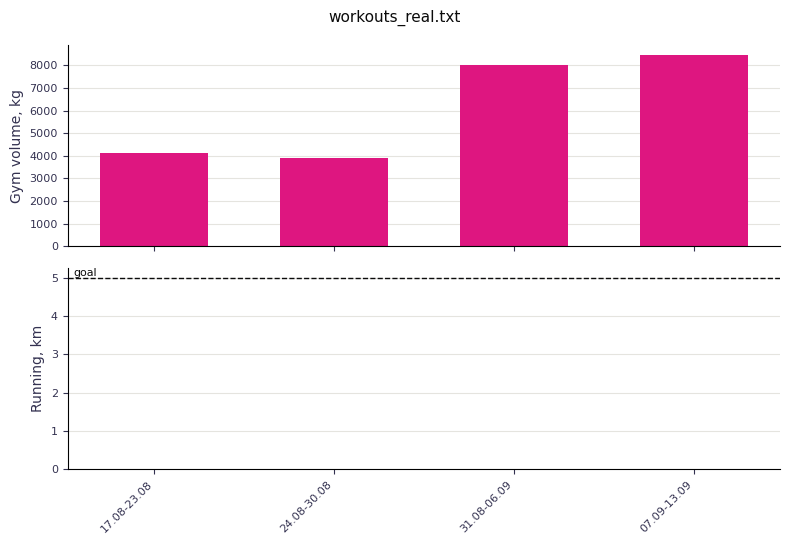

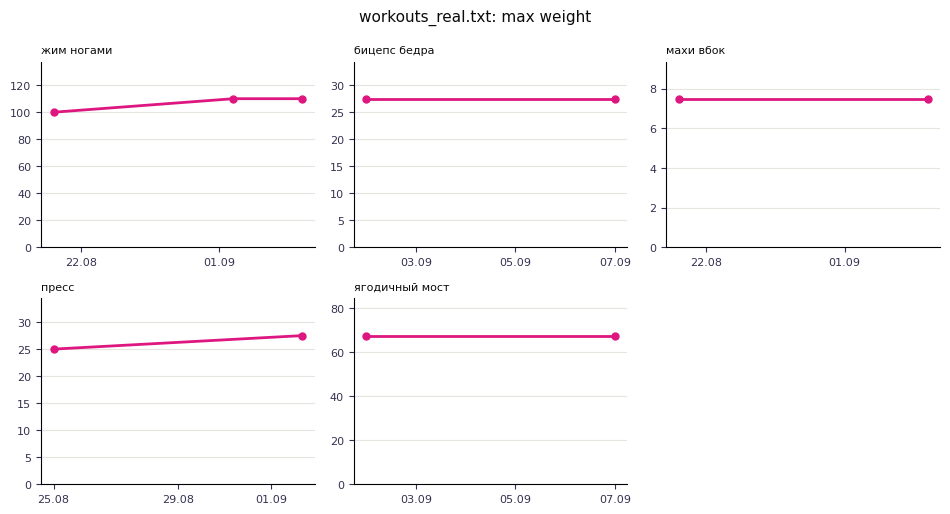

TRAINING REPORT v2: workouts_real.txt
Period: 2026-08-20 to 2026-09-07 | training days: 4
Valid entries: 16, rejected: 0, duplicates removed: 0
Weekly summary (weeks without workouts included):
            gym_days volume run_km gym_goal run_goal
17.08-23.08        1  4,130    0.0   MISSED   MISSED
24.08-30.08        1  3,892    0.0   MISSED   MISSED
31.08-06.09        1  8,036    0.0   MISSED   MISSED
07.09-13.09        1  8,472    0.0   MISSED   MISSED
Volume by muscle group:
  Legs            13,465 kg   55%
  Glutes           5,554 kg   23%
  Back             3,015 kg   12%
  Core             1,845 kg    8%
  Shoulders          382 kg    2%
  Arms               270 kg    1%
Not trained at all: Chest
Personal records (kg) and estimated 1RM:
  бицепс бедра                          27.5  02.09  1RM~  38.5  no change
  вертикальная тяга в кроссовере        35.0  25.08  1RM~  45.5  not enough data
  вертикальная тяга в тренажере         35.0  25.08  1RM~  45.5  not enough data
  горизон

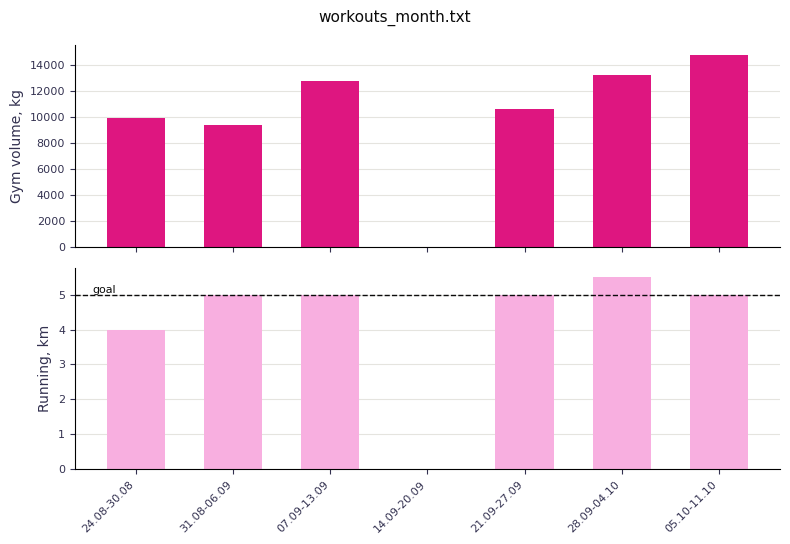

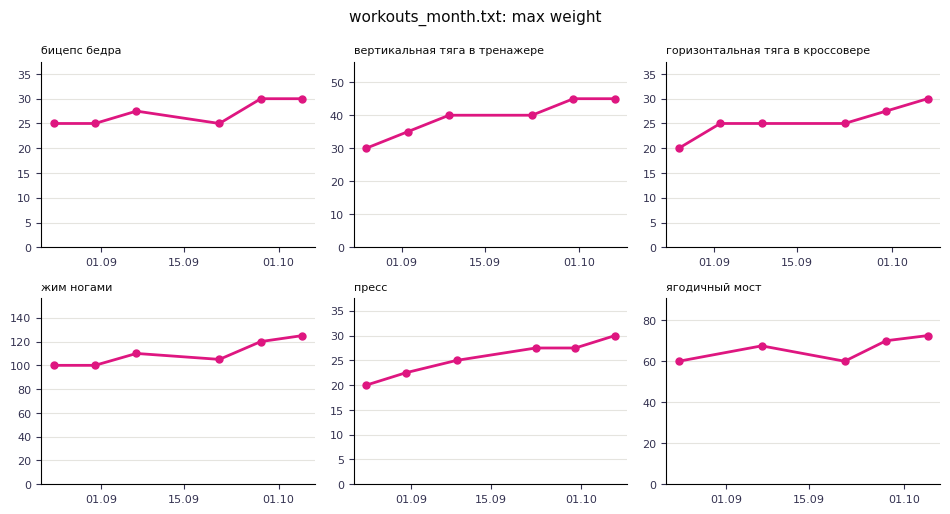

TRAINING REPORT v2: workouts_month.txt
Period: 2026-08-24 to 2026-10-10 | training days: 18
Valid entries: 54, rejected: 0, duplicates removed: 0
Weekly summary (weeks without workouts included):
            gym_days volume run_km gym_goal run_goal
24.08-30.08        2  9,905    4.0   ALMOST   ALMOST
31.08-06.09        2  9,368    5.0   ALMOST     DONE
07.09-13.09        2 12,770    5.0   ALMOST     DONE
14.09-20.09        0      0    0.0   MISSED   MISSED
21.09-27.09        2 10,621    5.0   ALMOST     DONE
28.09-04.10        2 13,220    5.5   ALMOST     DONE
05.10-11.10        2 14,765    5.0   ALMOST     DONE
Volume by muscle group:
  Legs            31,085 kg   44%
  Glutes          15,650 kg   22%
  Back            15,120 kg   21%
  Core             6,806 kg   10%
  Arms             1,380 kg    2%
  Shoulders          608 kg    1%
Not trained at all: Chest
Personal records (kg) and estimated 1RM:
  бицепс бедра                          30.0  28.09  1RM~  42.0  +5 kg since the firs

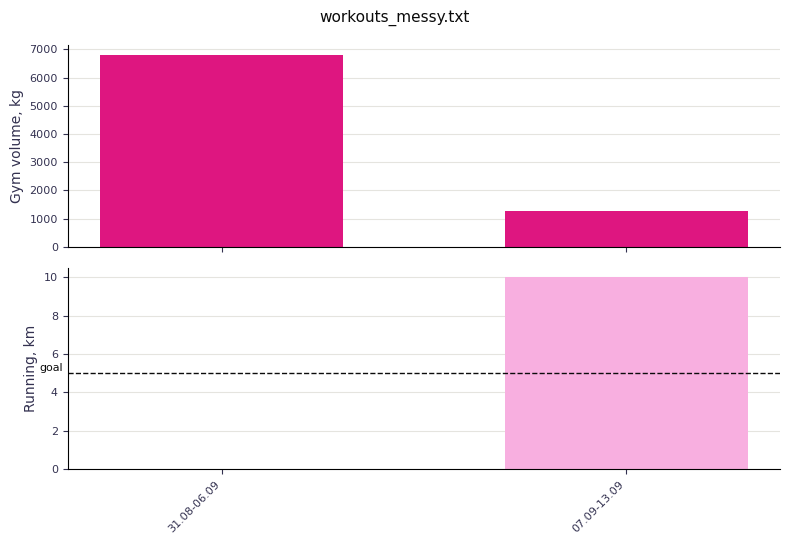

No exercise was repeated - no progress chart.
TRAINING REPORT v2: workouts_messy.txt
Period: 2026-09-02 to 2026-09-10 | training days: 3
Valid entries: 7, rejected: 12, duplicates removed: 1
Weekly summary (weeks without workouts included):
            gym_days volume run_km gym_goal run_goal
31.08-06.09        1  6,799    0.0   MISSED   MISSED
07.09-13.09        2  1,275   10.0   ALMOST     DONE
Volume by muscle group:
  Legs             5,145 kg   64%
  Glutes           1,654 kg   20%
  Core             1,125 kg   14%
  Other              150 kg    2%
Not trained at all: Arms, Back, Chest, Shoulders
Personal records (kg) and estimated 1RM:
  бицепс бедра                          27.5  02.09  1RM~  38.5  not enough data
  жим ногами                           110.0  02.09  1RM~ 146.7  not enough data
  пресс                                 25.0  10.09  1RM~  37.5  not enough data
  хождение на руках                     10.0  07.09  1RM~  11.7  not enough data
  ягодичный мост          

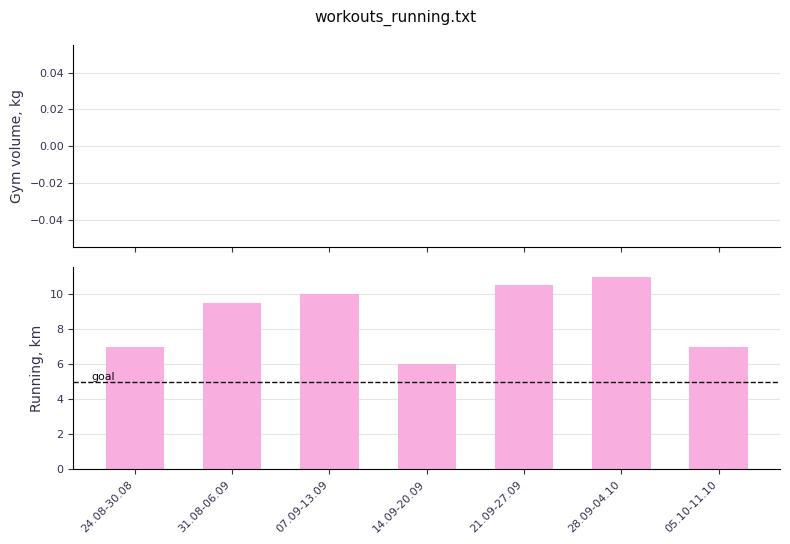

TRAINING REPORT v2: workouts_running.txt
Period: 2026-08-24 to 2026-10-09 | training days: 12
Valid entries: 12, rejected: 0, duplicates removed: 0
Weekly summary (weeks without workouts included):
            gym_days volume run_km gym_goal run_goal
24.08-30.08        0      0    7.0   MISSED     DONE
31.08-06.09        0      0    9.5   MISSED     DONE
07.09-13.09        0      0   10.0   MISSED     DONE
14.09-20.09        0      0    6.0   MISSED     DONE
21.09-27.09        0      0   10.5   MISSED     DONE
28.09-04.10        0      0   11.0   MISSED     DONE
05.10-11.10        0      0    7.0   MISSED     DONE
Running: 12 runs, 61.0 km, average pace 6:19/km, best 5:48/km
Break of 5 days: 27.08 -> 01.09
Break of 5 days: 16.09 -> 21.09
Break of 5 days: 25.09 -> 30.09
Break of 5 days: 04.10 -> 09.10
TRAINING REPORT v2: workouts_empty.txt
No valid workouts found - nothing to report.
Optimized version checks passed.


In [11]:
results = {}
for test_name in TEST_NAMES:
    results[test_name] = run_v2(DATA_DIR / f"{test_name}.txt", rules, goals,
                                YEAR, OUT_DIR)
    print(results[test_name]["report"])

month = results["workouts_month"]
assert len(month["weeks"]) == 7
empty_week = month["weeks"].loc["14.09-20.09"]
assert empty_week["gym_goal"] == "MISSED"
assert empty_week["run_goal"] == "MISSED"
messy = results["workouts_messy"]
assert results["workouts_running"]["gym"].empty
assert results["workouts_empty"]["weeks"].empty
print("Optimized version checks passed.")

Now I would like to compare the volume per muscle group in both versions. On the files without duplicates the numbers must be identical; on 'workouts_messy.txt' the difference is exactly the duplicated line (120 kg × 4 sets × 8 reps = 3840 kg of leg work).

In [12]:
for test_name in ["workouts_real", "workouts_month", "workouts_messy"]:
    entries, _ = read_workouts(DATA_DIR / f"{test_name}.txt", YEAR)
    v2_gym = results[test_name]["gym"]
    comparison = pd.DataFrame({
        "v1": volume_by_category(entries, rules),
        "v2": v2_gym.groupby("category")["volume"].sum().round(2),
    }).fillna(0.0)
    comparison["difference"] = (comparison["v1"] - comparison["v2"]).round(2)
    print(f"{test_name}:")
    print(comparison.to_string())
    if (comparison["difference"] == 0).all():
        print("-> identical results\n")
    else:
        print("-> versions differ: v2 removed the duplicated record\n")

workouts_real:
                 v1        v2  difference
Arms         270.00    270.00         0.0
Back        3015.00   3015.00         0.0
Core        1845.00   1845.00         0.0
Glutes      5553.75   5553.75         0.0
Legs       13465.00  13465.00         0.0
Shoulders    382.50    382.50         0.0
-> identical results

workouts_month:
                 v1        v2  difference
Arms        1380.00   1380.00         0.0
Back       15120.00  15120.00         0.0
Core        6806.25   6806.25         0.0
Glutes     15650.00  15650.00         0.0
Legs       31085.00  31085.00         0.0
Shoulders    607.50    607.50         0.0
-> identical results

workouts_messy:
             v1       v2  difference
Core    1125.00  1125.00         0.0
Glutes  1653.75  1653.75         0.0
Legs    6090.00  5145.00       945.0
Other    150.00   150.00         0.0
-> versions differ: v2 removed the duplicated record



<h2>6. Description of my technical solution and ideas for further development of the project</h2><a name=point6></a>

The main advantage is that my messy free-form notes, which were really hard to analyse by hand, become a clear weekly report really fast, and the program does not crash on bad lines, intead of this happening, it lists them with a reason!
Optimized version (2 version) is shorter in the analysis part, since I used pandas, also it shows the weeks i skipped completely and gives charts and csv files that i can open in spreadsheet.
I would also note that there are some disadvantages. For example, muscle groups depend on hand-written keywords.
For the next steps, I would read the notes directly from the phone notes export or something like this, also i would import runs from Strava export, for example, and send weekly report to myself with a Telegram bot(: